# 03 — Model finalny (LightGBM) i jednorazowa ocena na testach

1. Model finalny: LightGBM, z 5-krotną CV na pełnym `train` dla 3 najlepszych konfiguracji z próbki.
2. Progi decyzyjne: sprawdzone na CV z treningu (nie dały poprawy, zostaje `argmax`).
3. Trening na całym `train`, **jedna** ocena na `test_in` i `test_out`, przedziały bootstrap 95%.

Domyślnie wczytuje zapisane wyniki. `RECOMPUTE = True` liczy od nowa (~30 min).

In [1]:
import sys, warnings
sys.path.append('..')
warnings.filterwarnings('ignore')
import pandas as pd
pd.set_option('display.precision', 3)
import json
from src.experiment import RESULTS_DIR
from src import plots

RECOMPUTE = False

In [2]:
if RECOMPUTE:
    import joblib
    from src.experiment import load_all
    from src.evaluate import to_3_classes
    from src.final import (top_configs, full_train_cv, tune_class_scaling, fit_final_model,
                           evaluate_on_test, four_class_reference, FINAL_MODEL_PATH)
    df = load_all()
    train = df[df['split'] == 'train'].reset_index(drop=True)
    y = to_3_classes(train['Severity'].to_numpy())
    table, oof, params, folds = full_train_cv(train, y, top_configs(3))
    table.to_csv(f'{RESULTS_DIR}/full_train_cv_lightgbm.csv', index=False)
    scaling, check = tune_class_scaling(oof, y, folds)
    check.to_csv(f'{RESULTS_DIR}/threshold_check.csv', index=False)
    json.dump({'params': params, 'scaling': list(scaling)}, open(f'{RESULTS_DIR}/final_config.json', 'w'), indent=2)
    model = fit_final_model(train, y, params)
    joblib.dump(model, FINAL_MODEL_PATH)
    tests = {}
    for part in ['test_in', 'test_out']:
        test = df[df['split'] == part].reset_index(drop=True)
        tests[part] = test
        res = evaluate_on_test(model, scaling, test, to_3_classes(test['Severity'].to_numpy()))
        res['metrics'].to_csv(f'{RESULTS_DIR}/test_{part}_metrics.csv')
        res['by_source'].to_csv(f'{RESULTS_DIR}/test_{part}_by_source.csv')
        res['by_year'].to_csv(f'{RESULTS_DIR}/test_{part}_by_year.csv')
        res['confusion'].to_csv(f'{RESULTS_DIR}/test_{part}_confusion.csv')
    four_class_reference(train, tests, params).to_csv(f'{RESULTS_DIR}/test_4class_auxiliary.csv')

## CV na pełnym treningu (wybór konfiguracji)

In [3]:
pd.read_csv(f'{RESULTS_DIR}/full_train_cv_lightgbm.csv')

,weight_power,subsample_freq,subsample,reg_lambda,num_leaves,n_estimators,min_child_samples,learning_rate,colsample_bytree,macro_f1_mean,macro_f1_std,qwk_mean,seconds
0,1.0,1,0.8,0.0,127,200,20,0.05,1.0,0.603,7.269e-04,0.381,149.338
1,0.5,1,0.8,0.0,63,400,100,0.03,0.8,0.676,4.759e-03,0.715,198.742
2,0.5,1,0.8,5.0,127,800,50,0.05,0.8,0.726,5.501e-03,0.757,375.870


In [4]:
# Kontrola progów: mnożniki dobrane na 4 foldach, ocenione na piątym
pd.read_csv(f'{RESULTS_DIR}/threshold_check.csv')

,fold,scaling,macro_f1_argmax,macro_f1_scaled
0,0,"(1.0, 0.75, 1.0)",0.728,0.728
1,1,"(1.0, 0.75, 1.0)",0.731,0.730
2,2,"(1.0, 1.0, 1.0)",0.727,0.727
3,3,"(1.0, 1.0, 1.0)",0.716,0.716
4,4,"(1.0, 0.75, 1.0)",0.727,0.726


In [5]:
json.load(open(f'{RESULTS_DIR}/final_config.json'))

{'params': {'weight_power': 0.5,
  'subsample_freq': 1,
  'subsample': 0.8,
  'reg_lambda': 5.0,
  'num_leaves': 127,
  'n_estimators': 800,
  'min_child_samples': 50,
  'learning_rate': 0.05,
  'colsample_bytree': 0.8},
 'scaling': [1.0, 1.0, 1.0]}

## Wyniki na testach (95% przedział bootstrap)

In [6]:
test_in = pd.read_csv(f'{RESULTS_DIR}/test_test_in_metrics.csv', index_col=0)
test_out = pd.read_csv(f'{RESULTS_DIR}/test_test_out_metrics.csv', index_col=0)
pd.concat({'test_in (2016–2021)': test_in, 'test_out (2022–2023)': test_out}, axis=1)

test_in (2016–2021)                test_out (2022–2023)         \
                            value ci_low ci_high                value ci_low   
macro_f1                    0.735  0.727   0.742            5.905e-01  0.589   
balanced_acc                0.740  0.731   0.748            6.343e-01  0.633   
qwk                         0.760  0.756   0.765            5.161e-01  0.508   
recall_Sev1-2               0.949  0.948   0.950            9.877e-01  0.987   
recall_Sev3                 0.877  0.874   0.880            9.149e-01  0.910   
recall_Sev4                 0.392  0.367   0.417            2.974e-04  0.000   

                          
                 ci_high  
macro_f1       5.923e-01  
balanced_acc   6.358e-01  
qwk            5.238e-01  
recall_Sev1-2  9.880e-01  
recall_Sev3    9.197e-01  
recall_Sev4    9.086e-04

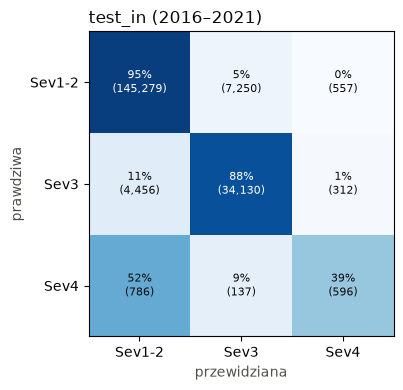

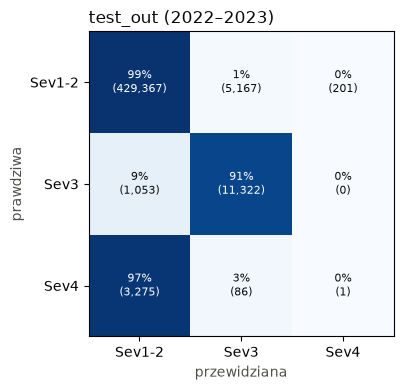

In [7]:
for part, title in [('test_in', 'test_in (2016–2021)'), ('test_out', 'test_out (2022–2023)')]:
    confusion = pd.read_csv(f'{RESULTS_DIR}/test_{part}_confusion.csv', index_col=0)
    plots.confusion_heatmap(confusion, title=title)

## Per źródło i per rok

W `test_out` model w `Source1` przewiduje wyłącznie Sev1-2 — Sev4 z 2022 r. nie jest rozpoznawana.
Już w `test_in` wynik spada z roku na rok, co jest skutkiem zmian w sposobie etykietowania.

In [8]:
pd.concat({'test_in': pd.read_csv(f'{RESULTS_DIR}/test_test_in_by_source.csv', index_col=0),
           'test_out': pd.read_csv(f'{RESULTS_DIR}/test_test_out_by_source.csv', index_col=0)})

macro_f1  balanced_acc        qwk  recall_Sev1-2  \
test_in  Source1     0.523         0.506  4.344e-01          0.993   
         Source2     0.604         0.608  7.952e-01          0.871   
         Source3     0.584         0.597  7.542e-01          0.847   
test_out Source1     0.332         0.500 -3.465e-04          1.000   
         Source2     0.544         0.563  6.380e-01          0.774   
         Source3     0.571         0.597  7.182e-01          0.880   

                  recall_Sev3  recall_Sev4         n  
test_in  Source1        0.101    4.235e-01  103441.0  
         Source2        0.944    9.091e-03   83197.0  
         Source3        0.944    0.000e+00    6865.0  
test_out Source1        0.000    3.059e-04  413496.0  
         Source2        0.915    0.000e+00   32312.0  
         Source3        0.910    0.000e+00    4664.0

In [9]:
pd.concat({'test_in': pd.read_csv(f'{RESULTS_DIR}/test_test_in_by_year.csv', index_col=0),
           'test_out': pd.read_csv(f'{RESULTS_DIR}/test_test_out_by_year.csv', index_col=0)})

macro_f1  balanced_acc        qwk  recall_Sev1-2  recall_Sev3  \
test_in  2016     0.756         0.801  7.738e-01          0.923        0.897   
         2017     0.764         0.809  7.810e-01          0.928        0.894   
         2018     0.750         0.780  7.701e-01          0.925        0.887   
         2019     0.730         0.702  7.384e-01          0.944        0.858   
         2020     0.677         0.664  6.318e-01          0.962        0.784   
         2021     0.636         0.670  6.648e-01          0.962        0.912   
test_out 2022     0.590         0.633  5.272e-01          0.985        0.915   
         2023     0.333         0.500 -8.777e-04          0.999        0.000   

               recall_Sev4       n  
test_in  2016    5.833e-01   20988  
         2017    6.066e-01   22994  
         2018    5.282e-01   23510  
         2019    3.048e-01   31998  
         2020    2.456e-01   42637  
         2021    1.347e-01   51376  
test_out 2022    3.197e-04  375913  
         2023    0.000e+00   74559

## Wynik pomocniczy: 4 klasy

Ten sam model wytrenowany na 4 klasach, tylko do porównania ze starym projektem
(stary RF: balanced accuracy 0,554, QWK 0,225 na losowym podziale bez `Source`).

In [10]:
pd.read_csv(f'{RESULTS_DIR}/test_4class_auxiliary.csv', index_col=0)

,macro_f1,balanced_acc,qwk,recall_Sev1,recall_Sev2,recall_Sev3,recall_Sev4
test_in,0.694,0.723,0.758,0.677,0.945,0.878,0.391
test_out,0.442,0.475,0.426,0.000,0.984,0.917,0.000
